In [5]:
import numpy as np
import time
import torch
import matplotlib.pyplot as plt
plt.rc('text', usetex=False)
import multiprocessing as mp
from typing import Union


from abc import ABC
from epde.preprocessing.cheb import process_point_cheb

from epde.preprocessing.deriv_calculators import Heatmap, AbstractDeriv, AdaptiveFiniteDeriv, PolynomialDeriv, SpectralDeriv, TotalVariation




Mean Squared Error (MSE) for noise level 0:
  u_tt: 0.002730296070509156
  u_t: 0.00021703513679364623
Mean Squared Error (MSE) for noise level 0.005:
  u_tt: 0.002470334915013726
  u_t: 0.00021986000393675302
Mean Squared Error (MSE) for noise level 0.01:
  u_tt: 0.003077474160953513
  u_t: 0.00027920761591901914


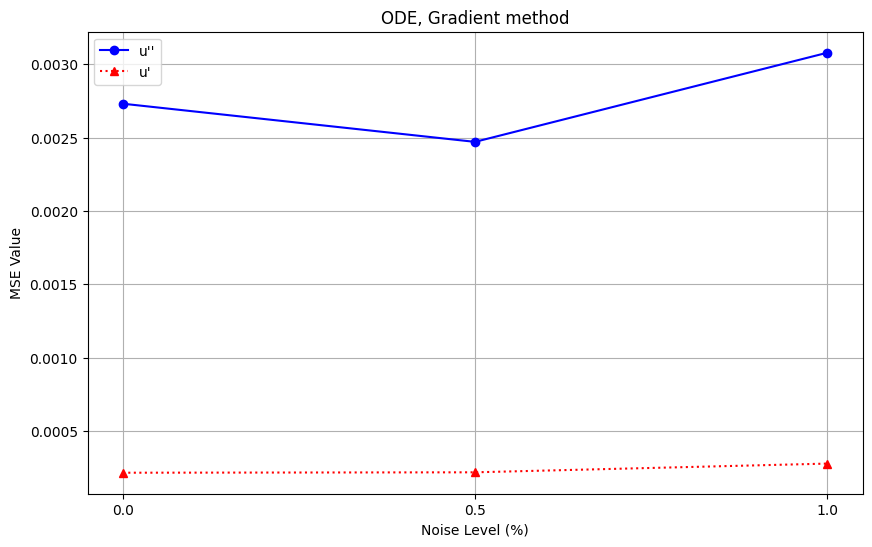

In [8]:
#ошибка дифференцирования между аналитической производной и численной для каждого слагаемого
import matplotlib as mpl
mpl.rc('text', usetex=False)
def calculate_mse(matrix1, matrix2):
    return np.mean((matrix1 - matrix2) ** 2)

noise_levels = [0, 0.005, 0.01]
noise_levels_percent = [0, 0.5, 1]

mse_values_u_tt = []
mse_values_u_t = []

for noise in noise_levels:
    u_tt = np.load(f'data_ode_noise{noise}_u_tt.npy')
    u_t = np.load(f'data_ode_noise{noise}_u_t.npy')
    
    gradient_tt = np.load(f'ode_Gradient_tt_noise{noise}.npy')
    gradient_t = np.load(f'ode_Gradient_t_noise{noise}.npy')
    
    u_tt = u_tt[5:27]
    u_t = u_t[5:27]
    

    gradient_tt = gradient_tt[5:27]
    gradient_t = gradient_t[5:27]
    # Вычисление MSE для каждого случая
    mse_u_tt = calculate_mse(u_tt, gradient_tt)
    mse_u_t = calculate_mse(u_t, gradient_t)
    
    mse_values_u_tt.append(mse_u_tt)
    mse_values_u_t.append(mse_u_t)
    
    print(f'Mean Squared Error (MSE) for noise level {noise}:')
    print(f'  u_tt: {mse_u_tt}')
    print(f'  u_t: {mse_u_t}')

plt.figure(figsize=(10, 6))
plt.plot(noise_levels_percent, mse_values_u_tt, marker='o', linestyle='-', color='b', label="u''")
plt.plot(noise_levels_percent, mse_values_u_t, marker='^', linestyle=':', color='r', label="u'")

plt.title('ODE, Gradient method')
plt.xlabel('Noise Level (%)')
plt.ylabel('MSE Value')
plt.xticks(noise_levels_percent)
plt.legend()
plt.grid()
plt.savefig('Ode_Gradient_error.pdf', format='pdf')
plt.show()


Mean Squared Error (MSE) for noise level 0:
  u_tt: 0.015519139459559793
  u_t: 0.0012059207600880763
Mean Squared Error (MSE) for noise level 0.005:
  u_tt: 0.015372583550180445
  u_t: 0.0012727039361449652
Mean Squared Error (MSE) for noise level 0.01:
  u_tt: 0.01577773184682866
  u_t: 0.0012729053990821087


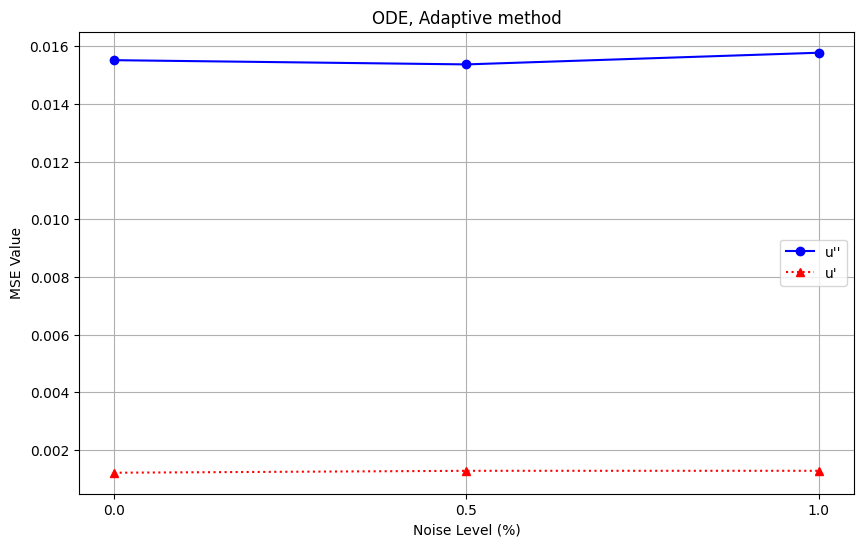

In [9]:
#ошибка дифференцирования между аналитической производной и численной для каждого слагаемого
import matplotlib as mpl
mpl.rc('text', usetex=False)
def calculate_mse(matrix1, matrix2):
    return np.mean((matrix1 - matrix2) ** 2)

noise_levels = [0, 0.005, 0.01]
noise_levels_percent = [0, 0.5, 1]

mse_values_u_tt = []
mse_values_u_t = []

for noise in noise_levels:
    u_tt = np.load(f'data_ode_noise{noise}_u_tt.npy')
    u_t = np.load(f'data_ode_noise{noise}_u_t.npy')
    
    gradient_tt = np.load(f'ode_Adaptive_tt_noise{noise}.npy')
    gradient_t = np.load(f'ode_Adaptive_t_noise{noise}.npy')

    u_tt = u_tt[5:27]
    u_t = u_t[5:27]
    

    gradient_tt = gradient_tt[5:27]
    gradient_t = gradient_t[5:27]
       
    # Вычисление MSE для каждого случая
    mse_u_tt = calculate_mse(u_tt, gradient_tt)
    mse_u_t = calculate_mse(u_t, gradient_t)
    
    mse_values_u_tt.append(mse_u_tt)
    mse_values_u_t.append(mse_u_t)
    
    print(f'Mean Squared Error (MSE) for noise level {noise}:')
    print(f'  u_tt: {mse_u_tt}')
    print(f'  u_t: {mse_u_t}')

plt.figure(figsize=(10, 6))
plt.plot(noise_levels_percent, mse_values_u_tt, marker='o', linestyle='-', color='b', label="u''")
plt.plot(noise_levels_percent, mse_values_u_t, marker='^', linestyle=':', color='r', label="u'")

plt.title('ODE, Adaptive method')
plt.xlabel('Noise Level (%)')
plt.ylabel('MSE Value')
plt.xticks(noise_levels_percent)
plt.legend()
plt.grid()
plt.savefig('Ode_Adaptive_error.pdf', format='pdf')
plt.show()


Mean Squared Error (MSE) for noise level 0:
  u_tt: 0.018984719149186265
  u_t: 0.012767472559212652
Mean Squared Error (MSE) for noise level 0.005:
  u_tt: 0.018837053316362946
  u_t: 0.012859395705132358
Mean Squared Error (MSE) for noise level 0.01:
  u_tt: 0.020169403793480974
  u_t: 0.012755942603950294


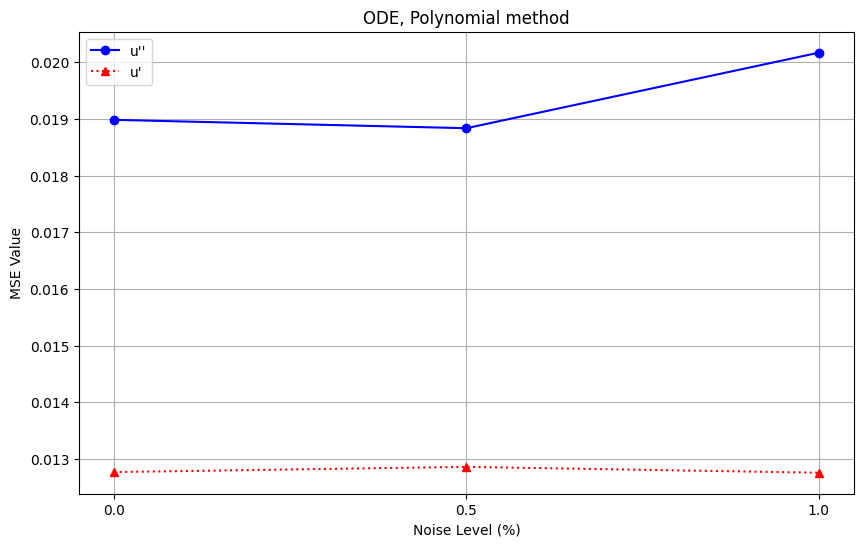

In [7]:
#ошибка дифференцирования между аналитической производной и численной для каждого слагаемого
import matplotlib as mpl
mpl.rc('text', usetex=False)
def calculate_mse(matrix1, matrix2):
    return np.mean((matrix1 - matrix2) ** 2)

noise_levels = [0, 0.005, 0.01]
noise_levels_percent = [0, 0.5, 1]

mse_values_u_tt = []
mse_values_u_t = []

for noise in noise_levels:
    u_tt = np.load(f'data_ode_noise{noise}_u_tt.npy')
    u_t = np.load(f'data_ode_noise{noise}_u_t.npy')
    
    gradient_tt = np.load(f'ode_Polynomial_tt_noise{noise}.npy')
    gradient_t = np.load(f'ode_Polynomial_t_noise{noise}.npy')

    u_tt = u_tt[5:27]
    u_t = u_t[5:27]
    

    gradient_tt = gradient_tt[5:27]
    gradient_t = gradient_t[5:27]
       
    # Вычисление MSE для каждого случая
    mse_u_tt = calculate_mse(u_tt, gradient_tt)
    mse_u_t = calculate_mse(u_t, gradient_t)
    
    mse_values_u_tt.append(mse_u_tt)
    mse_values_u_t.append(mse_u_t)
    
    print(f'Mean Squared Error (MSE) for noise level {noise}:')
    print(f'  u_tt: {mse_u_tt}')
    print(f'  u_t: {mse_u_t}')

plt.figure(figsize=(10, 6))
plt.plot(noise_levels_percent, mse_values_u_tt, marker='o', linestyle='-', color='b', label="u''")
plt.plot(noise_levels_percent, mse_values_u_t, marker='^', linestyle=':', color='r', label="u'")

plt.title('ODE, Polynomial method')
plt.xlabel('Noise Level (%)')
plt.ylabel('MSE Value')
plt.xticks(noise_levels_percent)
plt.legend()
plt.grid()
plt.savefig('Ode_Polynomial_error.pdf', format='pdf')
plt.show()


Mean Squared Error (MSE) for noise level 0:
  u_tt: 0.06870672774375101
  u_t: 0.005645239164430508
Mean Squared Error (MSE) for noise level 0.005:
  u_tt: 0.06937811493803082
  u_t: 0.005543482781947729
Mean Squared Error (MSE) for noise level 0.01:
  u_tt: 0.06944630658822412
  u_t: 0.005720606459732367


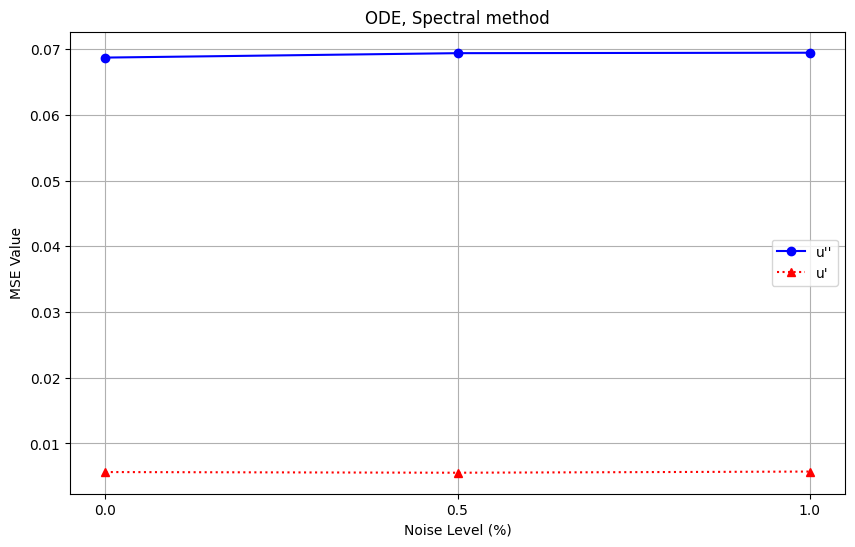

In [8]:
#ошибка дифференцирования между аналитической производной и численной для каждого слагаемого
import matplotlib as mpl
mpl.rc('text', usetex=False)
def calculate_mse(matrix1, matrix2):
    return np.mean((matrix1 - matrix2) ** 2)

noise_levels = [0, 0.005, 0.01]
noise_levels_percent = [0, 0.5, 1]

mse_values_u_tt = []
mse_values_u_t = []

for noise in noise_levels:
    u_tt = np.load(f'data_ode_noise{noise}_u_tt.npy')
    u_t = np.load(f'data_ode_noise{noise}_u_t.npy')
    
    gradient_tt = np.load(f'ode_Spectral_tt_noise{noise}.npy')
    gradient_t = np.load(f'ode_Spectral_t_noise{noise}.npy')

    u_tt = u_tt[5:27]
    u_t = u_t[5:27]
    

    gradient_tt = gradient_tt[5:27]
    gradient_t = gradient_t[5:27]
       
    # Вычисление MSE для каждого случая
    mse_u_tt = calculate_mse(u_tt, gradient_tt)
    mse_u_t = calculate_mse(u_t, gradient_t)
    
    mse_values_u_tt.append(mse_u_tt)
    mse_values_u_t.append(mse_u_t)
    
    print(f'Mean Squared Error (MSE) for noise level {noise}:')
    print(f'  u_tt: {mse_u_tt}')
    print(f'  u_t: {mse_u_t}')

plt.figure(figsize=(10, 6))
plt.plot(noise_levels_percent, mse_values_u_tt, marker='o', linestyle='-', color='b', label="u''")
plt.plot(noise_levels_percent, mse_values_u_t, marker='^', linestyle=':', color='r', label="u'")

plt.title('ODE, Spectral method')
plt.xlabel('Noise Level (%)')
plt.ylabel('MSE Value')
plt.xticks(noise_levels_percent)
plt.legend()
plt.grid()
plt.savefig('Ode_Spectral_error.pdf', format='pdf')
plt.show()


Mean Squared Error (MSE) for noise level 0:
  u_tt: 3.5606792487848207
  u_t: 0.9548142180779114
Mean Squared Error (MSE) for noise level 0.005:
  u_tt: 3.452319815713479
  u_t: 0.9519886722450761
Mean Squared Error (MSE) for noise level 0.01:
  u_tt: 3.1546653021587843
  u_t: 0.9606687135439338


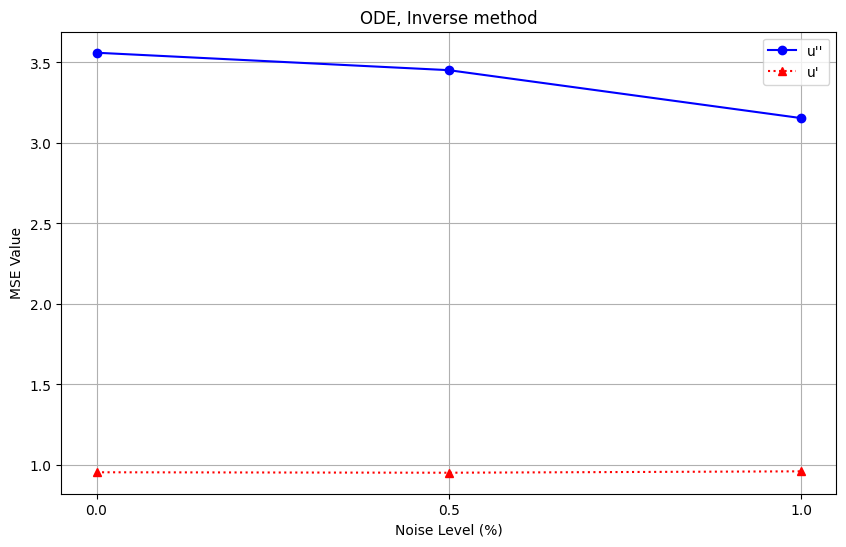

In [11]:
#ошибка дифференцирования между аналитической производной и численной для каждого слагаемого
import matplotlib as mpl
mpl.rc('text', usetex=False)
def calculate_mse(matrix1, matrix2):
    return np.mean((matrix1 - matrix2) ** 2)

noise_levels = [0, 0.005, 0.01]
noise_levels_percent = [0, 0.5, 1]

mse_values_u_tt = []
mse_values_u_t = []

for noise in noise_levels:
    u_tt = np.load(f'data_ode_noise{noise}_u_tt.npy')
    u_t = np.load(f'data_ode_noise{noise}_u_t.npy')
    
    gradient_tt = np.load(f'ode_Inverse_tt_noise{noise}.npy')
    gradient_t = np.load(f'ode_Inverse_t_noise{noise}.npy')

    u_tt = u_tt[5:27]
    u_t = u_t[5:27]
    

    gradient_tt = gradient_tt[5:27]
    gradient_t = gradient_t[5:27]
       
    # Вычисление MSE для каждого случая
    mse_u_tt = calculate_mse(u_tt, gradient_tt)
    mse_u_t = calculate_mse(u_t, gradient_t)
    
    mse_values_u_tt.append(mse_u_tt)
    mse_values_u_t.append(mse_u_t)
    
    print(f'Mean Squared Error (MSE) for noise level {noise}:')
    print(f'  u_tt: {mse_u_tt}')
    print(f'  u_t: {mse_u_t}')

plt.figure(figsize=(10, 6))
plt.plot(noise_levels_percent, mse_values_u_tt, marker='o', linestyle='-', color='b', label="u''")
plt.plot(noise_levels_percent, mse_values_u_t, marker='^', linestyle=':', color='r', label="u'")

plt.title('ODE, Inverse method')
plt.xlabel('Noise Level (%)')
plt.ylabel('MSE Value')
plt.xticks(noise_levels_percent)
plt.legend()
plt.grid()
plt.savefig('Ode_Inverse_error.pdf', format='pdf')
plt.show()


Mean Squared Error (MSE) for noise level 0:
  u_tt: 1.7064560106028366
  u_t: 0.6169738668991025
Mean Squared Error (MSE) for noise level 0.005:
  u_tt: 1.6974943142572776
  u_t: 0.6165921777349065
Mean Squared Error (MSE) for noise level 0.01:
  u_tt: 1.716334533806895
  u_t: 0.6155341489052703


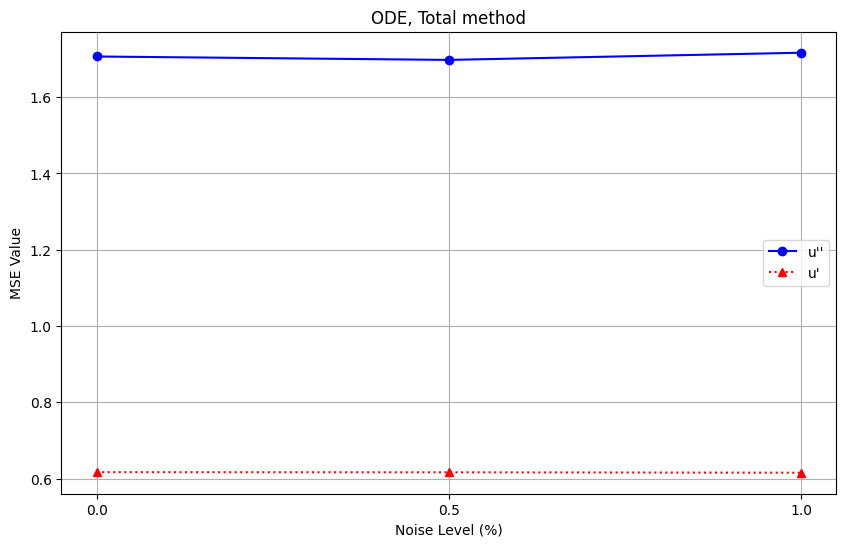

In [3]:
#ошибка дифференцирования между аналитической производной и численной для каждого слагаемого
import matplotlib as mpl
mpl.rc('text', usetex=False)
def calculate_mse(matrix1, matrix2):
    return np.mean((matrix1 - matrix2) ** 2)

noise_levels = [0, 0.005, 0.01]
noise_levels_percent = [0, 0.5, 1]

mse_values_u_tt = []
mse_values_u_t = []

for noise in noise_levels:
    u_tt = np.load(f'data_ode_noise{noise}_u_tt.npy')
    u_t = np.load(f'data_ode_noise{noise}_u_t.npy')
    
    gradient_tt = np.load(f'ode_Total_tt_noise{noise}.npy')
    gradient_t = np.load(f'ode_Total_t_noise{noise}.npy')

    u_tt = u_tt[5:27]
    u_t = u_t[5:27]
    

    gradient_tt = gradient_tt[5:27]
    gradient_t = gradient_t[5:27]
        
    # Вычисление MSE для каждого случая
    mse_u_tt = calculate_mse(u_tt, gradient_tt)
    mse_u_t = calculate_mse(u_t, gradient_t)
    
    mse_values_u_tt.append(mse_u_tt)
    mse_values_u_t.append(mse_u_t)
    
    print(f'Mean Squared Error (MSE) for noise level {noise}:')
    print(f'  u_tt: {mse_u_tt}')
    print(f'  u_t: {mse_u_t}')

plt.figure(figsize=(10, 6))
plt.plot(noise_levels_percent, mse_values_u_tt, marker='o', linestyle='-', color='b', label="u''")
plt.plot(noise_levels_percent, mse_values_u_t, marker='^', linestyle=':', color='r', label="u'")

plt.title('ODE, Total method')
plt.xlabel('Noise Level (%)')
plt.ylabel('MSE Value')
plt.xticks(noise_levels_percent)
plt.legend()
plt.grid()
plt.savefig('Ode_Total_error.pdf', format='pdf')
plt.show()
